# Figure 2 — MF lines at the blastoderm stage (3 hpf)

**Run order:** fig2 → fig3 → fig5 → fig6 (this notebook has no upstream dependencies).

| Output | What | File (in `outputs/`) |
|---|---|---|
| **Fig 2B** | % of proteome differentially abundant between each pair of lines, 3 hpf | `fig2/fig2B_pct_matrix_3hpf` |
| **Fig 2C** | Kr / byn / zen boxplots across the four lines | `fig2/fig2C_gene_boxplots` |
| **Fig 2D** | FlyBase gene-group violins (top/bottom 5 labelled) | `fig2/fig2D_gene_group_violins` |
| **Fig S2A, S2B** | Replicate concordance (best pair per line) at 3 hpf and 7 hpf | `fig2/figS2_best_replicate_pair_density_b0`, `_b4` |
| **Supplementary Table S1** | All proteins at 3 hpf + log2FC / q / sig for the 6 comparisons | `supplementary_tables/Table_S1_MF_lines_3hpf.csv` |

Fig 2A is a schematic (not produced here).

**Inputs** (`raw data/`): `protein_quant_2228_cns15_b0.tsv`, `protein_quant_2229_cns16_b4.tsv` (Fig S2B only),
(`helper files/`) `genetable.xlsx`, `gene_group_data_fb_2025_05.tsv.gz`.

**Statistics** (shared with Fig 3E, defined in `common.py`): Welch t-test per protein, Benjamini–Hochberg FDR,
log2FC from replicate medians; significant = q < 0.05 and |log2FC| ≥ 1.
The % matrix uses each pair's own 8-channel normalisation (S/N > 160); Table S1 uses the 16-channel dataset (S/N > 320).

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import common as cm

OUT = cm.fig_dir('fig2')
STAGE = 'b0'

datasets = cm.build_mf_datasets(STAGE)
results_pair, counts_pair = cm.run_mf_comparisons(datasets)          # Fig 2B
results_full, _           = cm.run_mf_comparisons(datasets, 'all')   # Table S1
result = datasets['all']                                              # Fig 2C, 2D

# Lookups keyed by full line name, in plot order NE, LP, DP, DE
tissues             = [c['full'] for c in cm.MF_CONDITIONS]
cond_to_cols        = {c['full']: cm.MF_COLS[c['short']] for c in cm.MF_CONDITIONS}
TISSUE_LABELS       = {c['full']: c['short'] for c in cm.MF_CONDITIONS}
TISSUE_COLORS_DARK  = {c['full']: c['dark'] for c in cm.MF_CONDITIONS}
TISSUE_COLORS_LIGHT = {c['full']: c['light'] for c in cm.MF_CONDITIONS}

  b0 all: 5,964 proteins
  b0 NE_LP: 5,952 proteins
  b0 NE_DP: 5,951 proteins
  b0 NE_DE: 5,965 proteins
  b0 LP_DP: 5,925 proteins
  b0 LP_DE: 5,945 proteins
  b0 DP_DE: 5,942 proteins


## Fig 2B — % of proteome differentially abundant (3 hpf)

NE_LP: 149/5952 = 2.5%
NE_DP: 145/5951 = 2.4%
NE_DE: 144/5965 = 2.4%
LP_DP: 130/5925 = 2.2%
LP_DE: 137/5945 = 2.3%
DP_DE: 97/5942 = 1.6%


Saved fig2/fig2B_pct_matrix_3hpf.pdf / .png


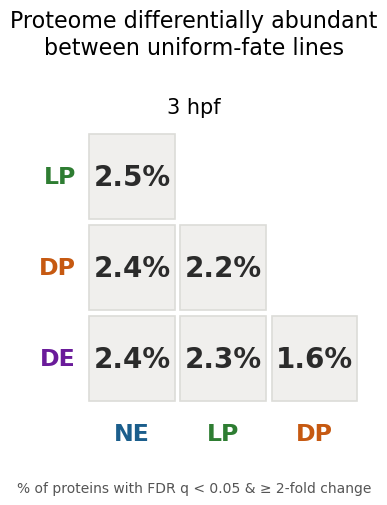

In [2]:
for key, (n_sig, total) in counts_pair.items():
    print(f'{key}: {n_sig}/{total} = {100 * n_sig / total:.1f}%')
fig = cm.plot_pct_matrix(counts_pair, STAGE)
cm.save_fig(fig, OUT, 'fig2B_pct_matrix_3hpf')
plt.show()

## Fig 2C — Kr, byn, zen across the four lines

Saved fig2/fig2C_gene_boxplots.pdf / .png


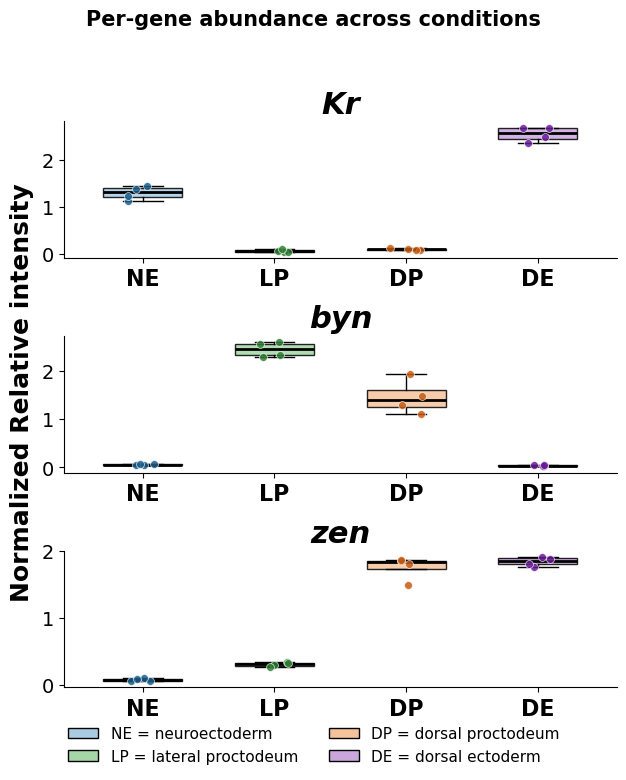

In [3]:
GENES = ['Kr', 'byn', 'zen']
rep_cols_all = [c for cols in cond_to_cols.values() for c in cols]
sym = result['gene_symbol'].astype(str)

def pick_row(sub):
    """Most complete protein row for a gene; tie-break on highest overall median."""
    if len(sub) == 1:
        return sub.iloc[0]
    completeness = sub[rep_cols_all].notna().sum(axis=1)
    sub = sub.loc[completeness == completeness.max()]
    if len(sub) > 1:
        sub = sub.loc[[sub[rep_cols_all].median(axis=1).idxmax()]]
    return sub.iloc[0]

nrows = len(GENES)
fig, axes = plt.subplots(nrows, 1, figsize=(6.2, 2.6 * nrows), squeeze=False)
rng = np.random.default_rng(0)
positions = list(range(len(tissues)))

for ax, gene in zip(axes[:, 0], GENES):
    row  = pick_row(result[sym == gene])
    data = [pd.to_numeric(row[cond_to_cols[t]], errors='coerce').dropna().to_numpy() for t in tissues]

    bp = ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', linewidth=2))
    for patch, t in zip(bp['boxes'], tissues):
        patch.set_facecolor(TISSUE_COLORS_LIGHT[t]); patch.set_edgecolor('black'); patch.set_alpha(0.85)
    for ln in bp['whiskers'] + bp['caps']:
        ln.set_color('black')
    for k, t in enumerate(tissues):
        ax.scatter(k + rng.uniform(-0.12, 0.12, size=len(data[k])), data[k], color=TISSUE_COLORS_DARK[t],
                   s=32, alpha=0.85, edgecolors='white', linewidth=0.5, zorder=3)

    ax.set_title(gene, fontsize=22, fontweight='bold', fontstyle='italic')
    ax.set_xticks(positions)
    ax.set_xticklabels([TISSUE_LABELS[t] for t in tissues], fontsize=16, fontweight='bold')
    ax.set_xlim(-0.6, len(tissues) - 0.4)
    ax.tick_params(axis='y', labelsize=14)
    ax.spines[['top', 'right']].set_visible(False)

fig.supylabel('Normalized Relative intensity', fontsize=18, fontweight='bold', x=0.01)
fig.suptitle('Per-gene abundance across conditions', fontsize=15, fontweight='bold', y=0.99)
handles = [mpatches.Patch(facecolor=TISSUE_COLORS_LIGHT[t], edgecolor='black', label=f'{TISSUE_LABELS[t]} = {t}')
           for t in tissues]
fig.legend(handles=handles, loc='lower center', ncol=2, fontsize=11, frameon=False, bbox_to_anchor=(0.5, 0.005))
fig.tight_layout(rect=[0, 0.07, 1, 0.93], pad=0.5, h_pad=1.0)
cm.save_fig(fig, OUT, 'fig2C_gene_boxplots')
plt.show()

## Fig 2D — FlyBase gene-group violins

Per protein, the median of the 4 replicates per line; only proteins with a finite median in all 4 lines are drawn.
The top 5 and bottom 5 proteins per line are labelled. Gene groups are matched by substring of `FB_group_name`.

26S PROTEASOME: 50 FBgn IDs -> 35 proteins
CYTOPLASMIC LARGE RIBOSOM: 54 FBgn IDs -> 44 proteins
MITOCHONDRIAL COMPLEX: 123 FBgn IDs -> 85 proteins
TRANSCRIPTION FACTORS: 623 FBgn IDs -> 194 proteins


Saved fig2/fig2D_gene_group_violins.pdf / .png


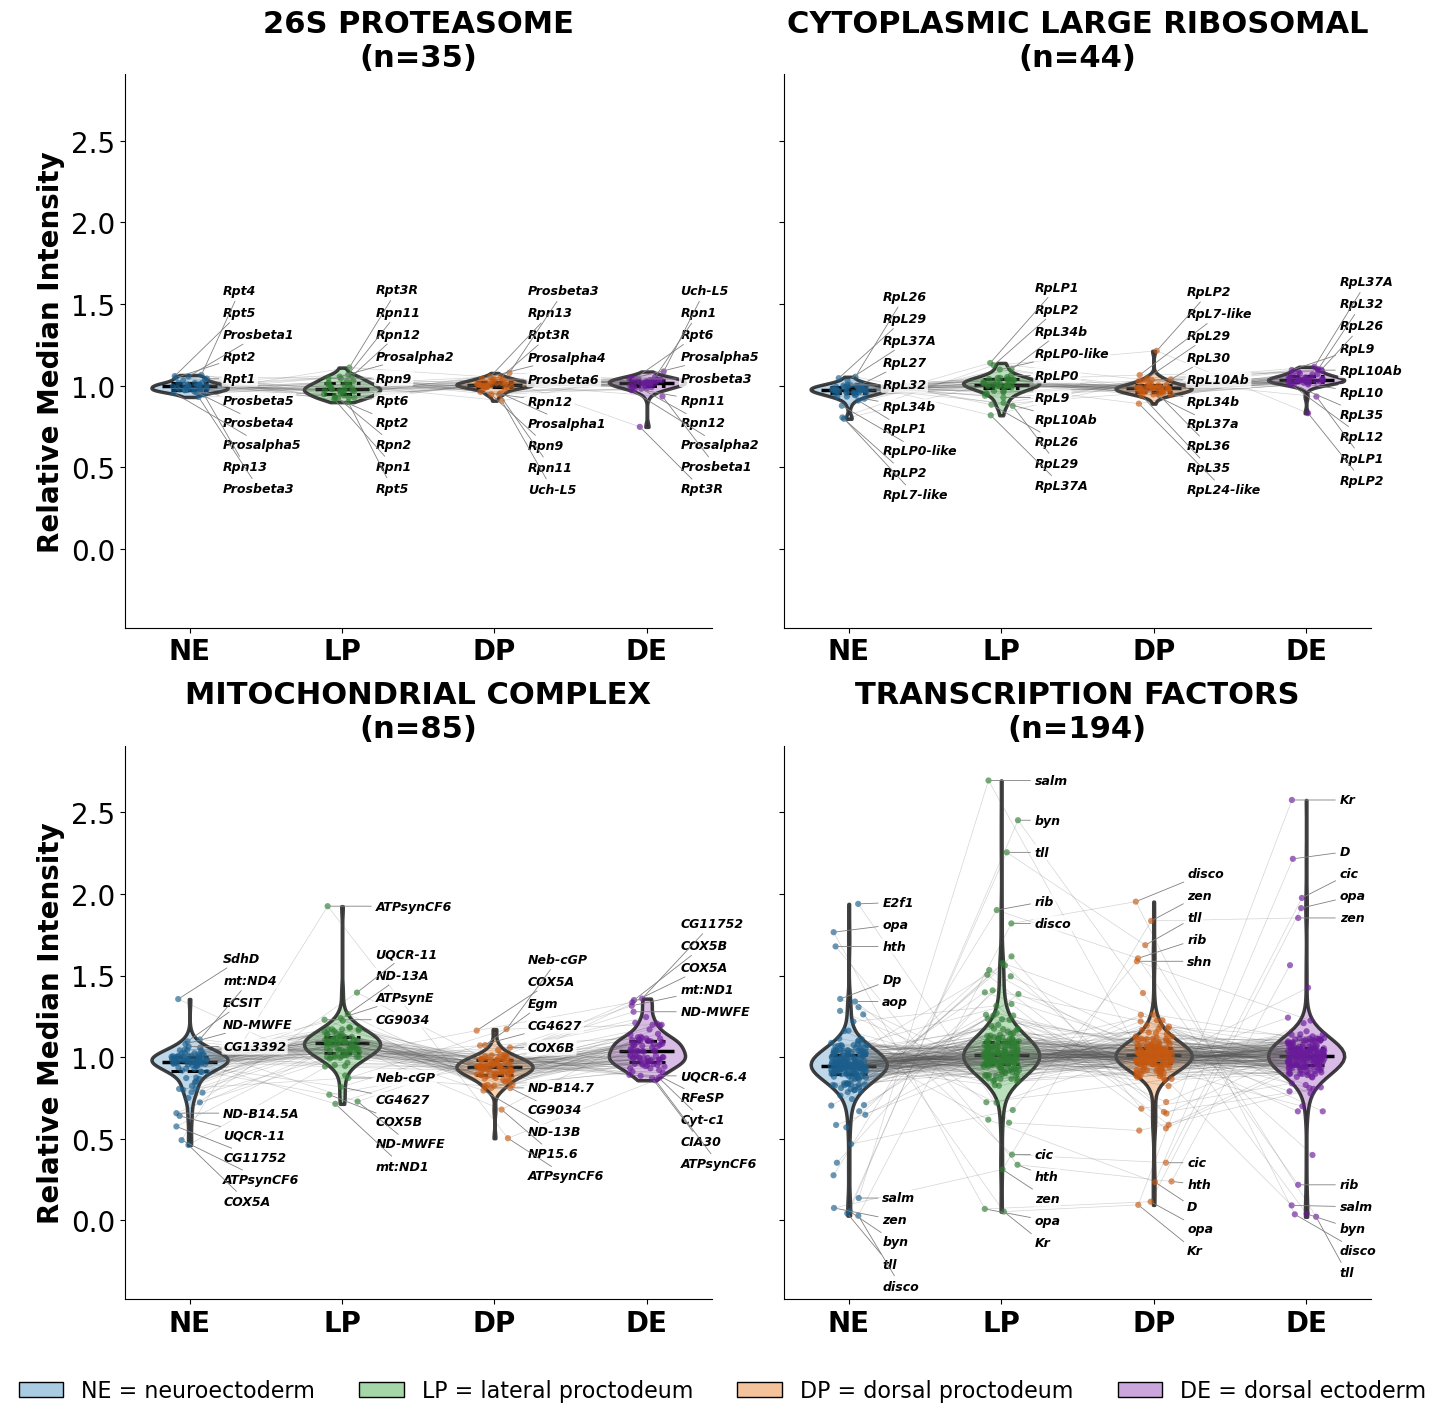

In [4]:
GROUPS = {                                   # search term -> panel title
    '26S PROTEASOME':            '26S PROTEASOME',
    'CYTOPLASMIC LARGE RIBOSOM': 'CYTOPLASMIC LARGE RIBOSOMAL',
    'MITOCHONDRIAL COMPLEX':     'MITOCHONDRIAL COMPLEX',
    'TRANSCRIPTION FACTORS':     'TRANSCRIPTION FACTORS',
}
TOP_N = BOTTOM_N = 5
LABEL_FS, LABEL_GAP = 9, 1.3                 # label font size; spacing between stacked labels (text heights)

FBGN_COL = cm.detect_fbgn_col(result, fallback='parent_value')
gg = cm.read_gene_groups()

family_tables = {}
for term in GROUPS:
    members = gg[gg['FB_group_name'].str.contains(term, case=False, na=False)]
    fbgns = set(members.drop_duplicates(subset=['Group_member_FB_gene_id'])['Group_member_FB_gene_id'])
    family_tables[term] = result[result[FBGN_COL].isin(fbgns)].copy()
    print(f'{term}: {len(fbgns)} FBgn IDs -> {len(family_tables[term])} proteins')


def stack_labels(vals, idx, min_gap, upward, start=None):
    """Greedy push-apart: [(j, label_y)] so labels are >= min_gap apart."""
    order = sorted(idx, key=lambda j: vals[j], reverse=not upward)
    placed, out = [], []
    for j in order:
        v = vals[j]
        if placed:
            y = max(v, placed[-1] + min_gap) if upward else min(v, placed[-1] - min_gap)
        elif start is not None:
            y = max(v, start) if upward else min(v, start)
        else:
            y = v
        placed.append(y); out.append((j, y))
    return out


def top_bottom_idx(vals, top_n, bottom_n):
    order_desc = np.argsort(vals)[::-1]
    top = list(order_desc[:top_n])
    bot = [j for j in order_desc[::-1][:bottom_n] if j not in set(top)]
    return top, bot


fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharey=True, squeeze=False)
positions, x_off = list(range(len(tissues))), 0.22

# Pass 1: violins, quartiles, points and per-protein lines
panels = []
for ax, term in zip(axes.flatten(), GROUPS):
    mdf = family_tables[term]
    med = {t: mdf[cond_to_cols[t]].median(axis=1).to_numpy(dtype=float) for t in tissues}
    valid = np.logical_and.reduce([np.isfinite(med[t]) for t in tissues])
    plot_data = [med[t][valid] for t in tissues]
    n_pts = int(valid.sum())
    rng = np.random.default_rng(42)
    jitters = {t: rng.uniform(-0.12, 0.12, size=n_pts) for t in tissues}

    parts = ax.violinplot(plot_data, positions=positions, showmeans=False, showmedians=False, showextrema=False)
    for pc, t in zip(parts['bodies'], tissues):
        pc.set_facecolor(TISSUE_COLORS_LIGHT[t]); pc.set_edgecolor('black'); pc.set_linewidth(2.5); pc.set_alpha(0.75)
    for pos, vals in zip(positions, plot_data):
        q25, q50, q75 = np.percentile(vals, [25, 50, 75])
        ax.hlines(q50, pos - 0.18, pos + 0.18, color='black', linewidth=2.5)
        ax.hlines([q25, q75], pos - 0.12, pos + 0.12, color='black', linewidth=2.2, linestyle='--')
    for j in range(n_pts):
        ax.plot([positions[k] + jitters[tissues[k]][j] for k in range(len(tissues))],
                [plot_data[k][j] for k in range(len(tissues))], color='#555555', linewidth=0.5, alpha=0.25, zorder=2)
    for k, t in enumerate(tissues):
        ax.scatter(positions[k] + jitters[t], plot_data[k], s=20, color=TISSUE_COLORS_DARK[t],
                   alpha=0.65, edgecolors='none', zorder=3)

    syms = mdf['gene_symbol'].astype(str).to_numpy()[valid]
    panels.append((ax, plot_data, jitters, syms))
    ax.set_title(f'{GROUPS[term]}\n(n={n_pts})', fontsize=22, fontweight='bold')
    ax.set_xticks(positions)
    ax.set_xticklabels([TISSUE_LABELS[t] for t in tissues], fontsize=20, fontweight='bold')
    ax.tick_params(axis='y', labelsize=20)
    ax.spines[['top', 'right']].set_visible(False)

# Shared y-range from the data (+8% headroom)
v = np.concatenate([np.asarray(d, float) for p in panels for d in p[1]])
lo, hi = float(np.nanmin(v)), float(np.nanmax(v))
ylim = (lo - 0.08 * (hi - lo), hi + 0.08 * (hi - lo))

# Pass 2: place labels a fixed number of text heights apart, widening the y-range until they fit
fig.canvas.draw()
for _ in range(4):
    specs_by_ax, new_lo, new_hi = {}, ylim[0], ylim[1]
    for ax, plot_data, jitters, syms in panels:
        ax_h_pts = ax.get_window_extent().height * 72 / fig.dpi
        min_gap = LABEL_GAP * LABEL_FS * 1.2 / ax_h_pts * (ylim[1] - ylim[0])
        specs = []
        for k, t in enumerate(tissues):
            vals = plot_data[k]
            top, bot = top_bottom_idx(vals, TOP_N, BOTTOM_N)
            top_pl = stack_labels(vals, top, min_gap, upward=True)
            cap    = min(y for _, y in top_pl) - min_gap if top_pl else None
            bot_pl = stack_labels(vals, bot, min_gap, upward=False, start=cap)
            for j, y in top_pl + bot_pl:
                specs.append((positions[k] + jitters[t][j], vals[j], positions[k] + x_off, y, syms[j]))
        specs_by_ax[id(ax)] = (ax, specs)
        ys = [s[3] for s in specs]
        if ys:
            new_lo, new_hi = min(new_lo, min(ys) - 0.6 * min_gap), max(new_hi, max(ys) + 0.6 * min_gap)
    if (new_lo, new_hi) == ylim:
        break
    ylim = (new_lo, new_hi)

for ax, *_ in panels:
    ax.set_ylim(*ylim)
for ax, specs in specs_by_ax.values():
    for xp, yp, xl, yl, txt in specs:
        ax.annotate(txt, xy=(xp, yp), xytext=(xl, yl), textcoords='data',
                    fontsize=LABEL_FS, fontweight='bold', fontstyle='italic', ha='left', va='center', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', lw=0.5, alpha=0.8),
                    arrowprops=dict(arrowstyle='-', color='gray', lw=0.6))

for r in range(2):
    axes[r, 0].set_ylabel('Relative Median Intensity', fontsize=20, fontweight='bold')
handles = [mpatches.Patch(facecolor=TISSUE_COLORS_LIGHT[t], edgecolor='black', label=f'{TISSUE_LABELS[t]} = {t}')
           for t in tissues]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=16, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=[0, 0.03, 1, 1])
cm.save_fig(fig, OUT, 'fig2D_gene_group_violins')
plt.show()

## Fig S2A, S2B — replicate concordance at 3 hpf and 7 hpf

16-channel dataset of each stage (S/N > 320). For each line the replicate pair with the highest Pearson r is shown;
both stages share one axis range.

  b4 all: 5,953 proteins
  b4 NE_LP: 5,952 proteins
  b4 NE_DP: 5,945 proteins
  b4 NE_DE: 5,931 proteins
  b4 LP_DP: 5,945 proteins
  b4 LP_DE: 5,941 proteins
  b4 DP_DE: 5,911 proteins
=== blastoderm (3 hpf) ===
  NE: a~b 0.263, a~c 0.138, a~d -0.159, b~c 0.295, b~d 0.008, c~d 0.006  -> shown: NE_b vs NE_c (r = 0.295)
  LP: a~b 0.149, a~c 0.102, a~d 0.102, b~c 0.896, b~d 0.844, c~d 0.836  -> shown: LP_b vs LP_c (r = 0.896)
  DP: a~b 0.224, a~c 0.839, a~d 0.811, b~c 0.214, b~d 0.297, c~d 0.850  -> shown: DP_c vs DP_d (r = 0.850)
  DE: a~b 0.170, a~c 0.054, a~d 0.097, b~c 0.398, b~d 0.485, c~d 0.796  -> shown: DE_c vs DE_d (r = 0.796)
=== blastoderm +4 (7 hpf) ===
  NE: a~b 0.464, a~c 0.803, a~d 0.816, b~c 0.521, b~d 0.484, c~d 0.908  -> shown: NE_c vs NE_d (r = 0.908)
  LP: a~b 0.757, a~c 0.599, a~d 0.735, b~c 0.752, b~d 0.779, c~d 0.792  -> shown: LP_c vs LP_d (r = 0.792)
  DP: a~b 0.913, a~c 0.893, a~d 0.870, b~c 0.891, b~d 0.889, c~d 0.897  -> shown: DP_a vs DP_b (r = 0.913)
  DE: 

Saved fig2/figS2_best_replicate_pair_density_b0.pdf / .png


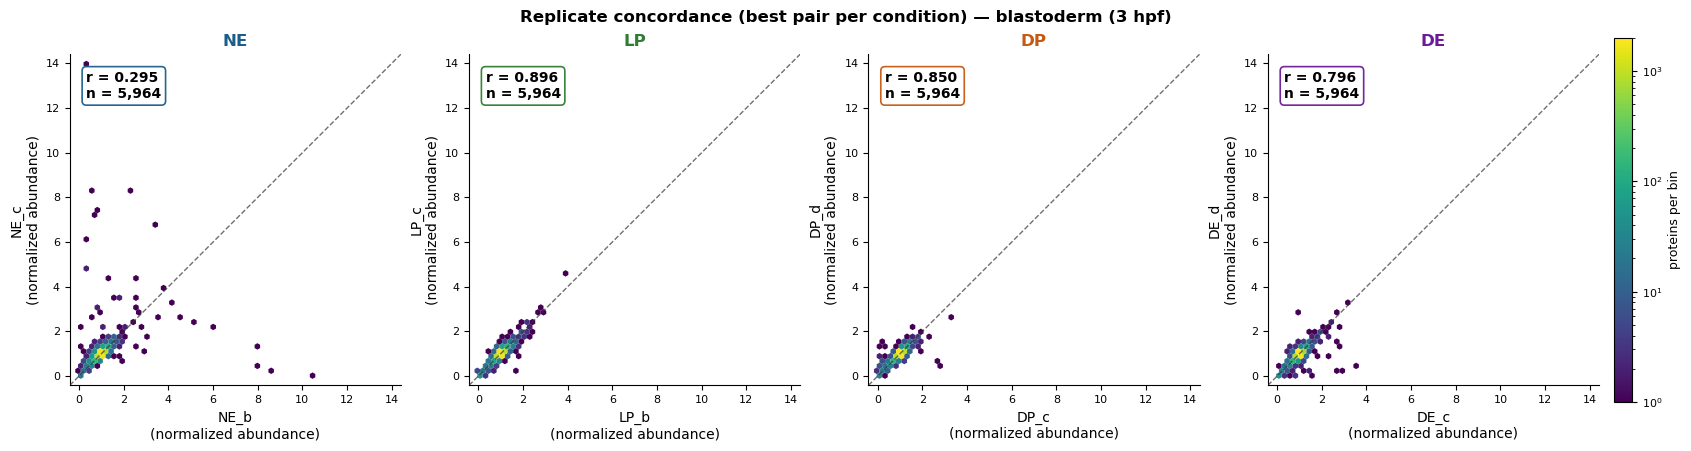

Saved fig2/figS2_best_replicate_pair_density_b4.pdf / .png


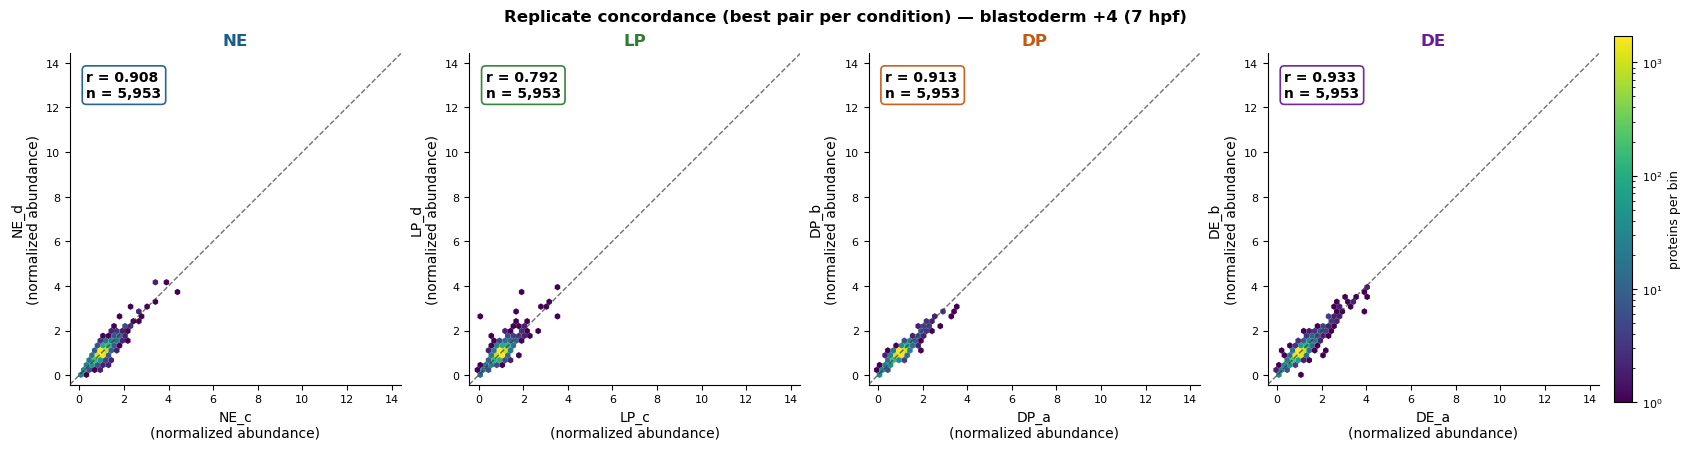

In [5]:
all_b4 = cm.build_mf_datasets('b4')['all']
cm.plot_best_replicate_density({'b0': result, 'b4': all_b4}, OUT)

## Supplementary Table S1

Protein abundance and pairwise differential-abundance statistics for the four MF lines at 3 hpf.

In [6]:
cm.save_table(cm.mf_stats_table(datasets, results_full), 'Table_S1_MF_lines_3hpf')

Saved Table_S1_MF_lines_3hpf.csv  (5,964 rows x 42 columns)
